# 9 · Filtres, projection et continuation

*Notebook 9 du cours. Il suppose le notebook 8 (SIMP, OC, damiers et dépendance au maillage).*

Le notebook 8 s'est terminé sur un constat : sans précaution, l'optimisation topologique n'a pas de solution « raisonnable ». Quand on raffine le maillage, elle ajoute des barres toujours plus fines, et elle fabrique des **damiers** que l'élément fini surestime. Pour un projet FDM il y a une deuxième raison d'agir : une buse a une largeur, et un trait plus fin qu'elle n'est pas imprimable. Il faut donc **imposer une taille minimale**. On le fait en trois temps :

1. un **filtre de densité** : la densité physique est une moyenne locale des variables de conception, sur un rayon $R$ ;
2. une **projection** de Heaviside qui raidit les contours que le filtre a rendus flous ;
3. une **continuation** qui introduit la projection progressivement, car l'imposer d'emblée échoue.

**Plan.**
1. Le filtre de densité : définition, normalisation, validations ;
2. La boucle avec filtre contre un top88 indépendant ;
3. Indépendance au maillage et fin des damiers ;
4. La projection de Heaviside ;
5. Pourquoi une continuation : la projection d'emblée échoue ;
6. La continuation en $\beta$ et en $p$ ;
7. La chaîne entière est dérivable ;
8. Bilan.

Ce notebook promeut dans `src` : `topopt/density.py` (`DensityFilter`, `heaviside_projection`, `DensityPipeline`), `optim/continuation.py` (`Schedule`), `optim/loop.py` (`run`), et `problem.py::ComplianceProblem` (le problème « compliance + volume » de bout en bout, à partir d'un cas nommé). Contrats : C-FILT-01 à 04, C-PROJ-01 à 03, C-MASK-01, C-OPT-02 (benchmark MBB), C-OPT-04 et 05 (continuation, arrêt).

In [1]:
import sys, time, inspect
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))
sys.path.insert(0, str(RACINE / "tests"))

from aeroptimizer.grid import Grid
from aeroptimizer.optim.continuation import Schedule
from aeroptimizer.optim.loop import run
from aeroptimizer.optim.oc import OC
from aeroptimizer.problem import ComplianceProblem
from aeroptimizer.topopt.density import DensityFilter, heaviside_projection
from reference.filter_numpy import apply_filter, filter_matrix      # oracle indépendant (boucles)
from reference.top88_numpy import top88                              # oracle indépendant (top88)

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

def montre(ax, rho, shape, titre="", miroir=False):
    # densité 2D, axe z vers le haut ; miroir=True reconstitue la poutre MBB entière
    img = np.asarray(rho).reshape(shape).T
    if miroir:
        img = np.hstack([img[:, ::-1], img])
    ax.imshow(img, origin="lower", cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(titre); ax.set_xticks([]); ax.set_yticks([])

grise = lambda r: float(((np.asarray(r) > 0.1) & (np.asarray(r) < 0.9)).mean())

## 1. Le filtre de densité

Soit $\mathbf x$ les variables de conception (une par élément). On ne calcule pas la mécanique sur $\mathbf x$ mais sur la **densité filtrée**

$$
\tilde\rho_e=\frac{\sum_f w_{ef}\,x_f}{\sum_f w_{ef}},\qquad w_{ef}=\max\!\Big(0,\ 1-\frac{\|\mathbf c_e-\mathbf c_f\|}{R}\Big),
$$

où $\mathbf c_e$ est le centre de l'élément $e$ et $R$ le **rayon du filtre** (en mètres : le filtre dépend de la longueur physique, pas du nombre d'éléments). Le noyau est un **cône** : poids 1 au centre, nul à distance $R$. Chaque $\tilde\rho_e$ est une moyenne pondérée de $\mathbf x$ autour de $e$.

Trois conséquences se vérifient et seront testées :
- **Normalisation.** Au bord d'un maillage il manque des voisins. Diviser par $\sum_f w_{ef}$ (la somme des poids *effectivement présents*) garde une moyenne pondérée, donc une densité constante reste constante, bords compris. Sans elle, la densité baisserait près des bords.
- **Convexité.** Une moyenne pondérée d'éléments de $[0,1]$ reste dans $[0,1]$.
- **Taille minimale.** Un élément isolé plein au milieu de vides est étalé sur un disque de rayon $R$ et perd son contraste : un détail plus petit que $R$ ne survit pas. Un damier (alternance à l'échelle d'un élément) devient un gris uniforme.

Implémentation (`DensityFilter`) : le noyau est échantillonné **une fois** sur $(2r_a+1)$ points par axe, $r_a=\lceil R/h_a\rceil-1$, appliqué par une convolution `conv2d`/`conv3d` à bords nuls, et divisé par la même convolution appliquée à un champ de 1 (précalculée).

In [2]:
grid = Grid((40, 24), (1.0, 1.0))
flt = DensityFilter(grid, R=4.0)
print("rayon discret par axe :", flt.radii, " noyau :", tuple(flt.kernel.shape[2:]), " somme des poids au centre (norm) :", float(flt.norm[20, 12]), "au coin :", float(flt.norm[0, 0]))

# 1) constantes, y compris aux bords ; 2) intervalle [0,1] ; 3) identité si R <= h
c = torch.full(grid.shape, 0.37)
print(f"filtre(0,37 partout) - 0,37 : écart max {float((flt(c) - 0.37).abs().max()):.1e}")
x_alea = (torch.rand(grid.shape, generator=torch.Generator().manual_seed(0)) > 0.5).double()
y = flt(x_alea)
print(f"entrée dans {{0,1}} -> sortie dans [{float(y.min()):.3f} ; {float(y.max()):.3f}]")
print("R = h : identité exacte ?", bool(torch.equal(DensityFilter(grid, 1.0)(x_alea), x_alea)))

# sans normalisation : la densité chuterait au bord
brut = flt._conv(torch.ones(grid.shape))
print(f"conv brute de 1 : {float(brut[20, 12]):.2f} au centre mais {float(brut[0, 0]):.2f} au coin ({100 * float(brut[0, 0] / brut[20, 12]):.0f} % du centre) -> d'où la division")

# comparaison avec un oracle indépendant (matrice dense, double boucle sur les éléments)
g_p = Grid((9, 6), (1.0, 1.0)); f_p = DensityFilter(g_p, R=2.5)
xp = torch.rand(g_p.shape, generator=torch.Generator().manual_seed(1))
W = filter_matrix(g_p.shape, g_p.h, 2.5)
print(f"écart avec l'oracle dense (9x6) : {np.abs(f_p(xp).reshape(-1).numpy() - apply_filter(W, xp.numpy())).max():.1e}")

rayon discret par axe : (3, 3)  noyau : (7, 7)  somme des poids au centre (norm) : 16.749565486616397 au coin : 6.437391371654099
filtre(0,37 partout) - 0,37 : écart max 1.1e-16
entrée dans {0,1} -> sortie dans [0.234 ; 0.815]
R = h : identité exacte ? True
conv brute de 1 : 16.75 au centre mais 6.44 au coin (38 % du centre) -> d'où la division
écart avec l'oracle dense (9x6) : 2.2e-16


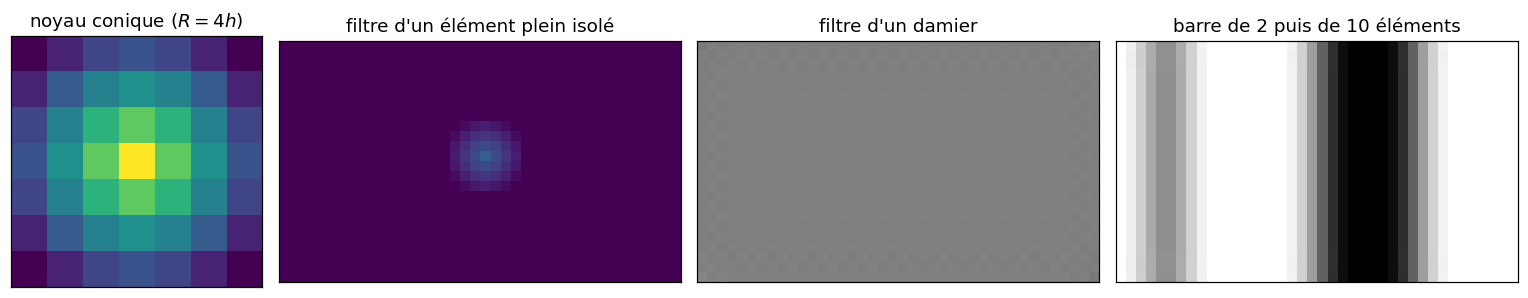

contraste après filtre : élément isolé 0.060 (de 1), damier 0.50 à 0.50, barre fine 0.44, barre épaisse 1.00


In [3]:
fig, ax = plt.subplots(1, 4, figsize=(14, 2.8), gridspec_kw={"width_ratios": [1, 1.6, 1.6, 1.6]})
ax[0].imshow(flt.kernel[0, 0].numpy().T, origin="lower", cmap="viridis"); ax[0].set_title("noyau conique ($R=4h$)")
# élément isolé
dirac = torch.zeros(grid.shape); dirac[20, 12] = 1.0
im = ax[1].imshow(flt(dirac).numpy().T, origin="lower", vmin=0, vmax=0.2); ax[1].set_title("filtre d'un élément plein isolé")
# damier -> gris
ii, jj = np.meshgrid(np.arange(40), np.arange(24), indexing="ij")
damier = torch.from_numpy(((ii + jj) % 2).astype(float))
ax[2].imshow(flt(damier).numpy().T, origin="lower", cmap="gray_r", vmin=0, vmax=1); ax[2].set_title("filtre d'un damier")
# barre fine vs barre épaisse
barres = torch.zeros(grid.shape); barres[4:6, :] = 1.0; barres[20:30, :] = 1.0
ax[3].imshow(flt(barres).numpy().T, origin="lower", cmap="gray_r", vmin=0, vmax=1); ax[3].set_title("barre de 2 puis de 10 éléments")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()
print(f"contraste après filtre : élément isolé {float(flt(dirac).max()):.3f} (de 1), damier {float(flt(damier)[10:30, 6:18].min()):.2f} à {float(flt(damier)[10:30, 6:18].max()):.2f}, barre fine {float(flt(barres)[5, 12]):.2f}, barre épaisse {float(flt(barres)[25, 12]):.2f}")

Un élément isolé tombe à 6 % de sa valeur, le damier devient un gris uniforme autour de 0,5, la barre de 2 éléments tombe à 0,44 alors que la barre de 10 éléments garde son cœur plein (1,00). C'est bien un contrôle de taille minimale, de l'ordre de $R$.

**Le gradient passe par le filtre.** Le filtre est linéaire, $\tilde{\boldsymbol\rho}=\mathbf D^{-1}\mathbf W\mathbf x$ avec $\mathbf D=\operatorname{diag}(\mathbf W\mathbf 1)$, donc $\partial\mathcal{C}/\partial\mathbf x=\mathbf W^\top\mathbf D^{-1}\,\partial\mathcal{C}/\partial\tilde{\boldsymbol\rho}$ : on reporte le gradient sur les voisins. Il n'y a rien à écrire : l'autograd le fait, et le test C-FILT-04 compare à cette formule dense et à `gradcheck`. (Le top88 d'origine l'écrit à la main : `dc = H*(dc./Hs)`.)

## 2. La boucle avec filtre contre un top88 indépendant

`ComplianceProblem` (`problem.py`) assemble tout : cas nommé (`build_case`), `DensityPipeline` (masques, filtre, projection), SIMP, `solve_spd` et compliance. Sa fonction `evaluate(x)` renvoie la compliance et la contrainte de volume **de la densité physique** $\bar\rho$ ; `run` (`optim/loop.py`) appelle l'optimiseur et applique un calendrier de continuation. Les dérivées de la chaîne $\mathbf x\to\tilde\rho\to\bar\rho\to s\to\mathbf u\to\mathcal{C}$ viennent de l'autograd, la seule règle écrite à la main restant l'adjoint (notebook 7).

**Validation.** Le top88 NumPy du dépôt (`tests/reference/top88_numpy.py`) accepte `ft=2` (filtre de densité). On compare les compliances sur 60 itérations, avec le même rayon ($R=1{,}5$ élément) et la même tolérance de bissection ($10^{-12}$).

In [4]:
const = Schedule(p=(3.0, 3.0), beta=(0.0, 0.0), beta_s=(1.0, 1.0))      # p = 3 fixe, pas de projection
n_it = 60
ref = top88(60, 20, 0.5, 3.0, 1.5, max_iter=n_it, ft=2, lam_tol=1e-12, change_tol=0.0)
pb = ComplianceProblem("mbb", (60, 20), volfrac=0.5, R=1.5)
res = run(pb, OC(tol=1e-12), const, max_iter=n_it, tol=0.0)
C = np.array([h["C"] for h in res.history])

print(f"{'itération':>10} | {'C (ComplianceProblem)':>22} | {'C (oracle top88)':>17} | écart relatif")
for it in (0, 1, 9, 29, 59):
    print(f"{it + 1:10d} | {C[it]:22.9f} | {ref['c'][it]:17.9f} | {abs(C[it] / ref['c'][it] - 1):.1e}")
print(f"écart relatif max sur les {n_it} itérations : {np.max(np.abs(C / np.array(ref['c']) - 1)):.1e}")
rb = pb.rho_bar(torch.from_numpy(res.x)).detach().numpy()
x_ref = np.flipud(ref["x"]).T.reshape(-1)
print(f"écart max sur la densité physique finale : {np.abs(rb - x_ref).max():.1e} ;  volume {rb.mean():.10f}")

 itération |  C (ComplianceProblem) |  C (oracle top88) | écart relatif
         1 |         1007.022100725 |    1007.022100723 | 1.8e-12
         2 |          577.406359131 |     577.406359139 | 1.5e-11
        10 |          283.151571739 |     283.151571739 | 1.3e-13
        30 |          222.098299146 |     222.098299145 | 2.4e-12
        60 |          220.397950672 |     220.397950671 | 6.4e-12
écart relatif max sur les 60 itérations : 1.5e-11
écart max sur la densité physique finale : 1.2e-09 ;  volume 0.5000000000


Les compliances coïncident à $10^{-11}$ près sur 60 itérations, et la densité physique à $10^{-9}$. La validation est exacte parce que le volume est calculé sur $\bar\rho$ (la densité filtrée) dans les deux codes ; c'est le test C-OPT-02 (benchmark MBB, à ±2 % du top88), tenu ici avec une marge énorme.

Remarque sur l'optimiseur : la contrainte de volume porte sur $\bar\rho(\mathbf x)$ et non plus sur $\mathbf x$. Elle n'est plus linéaire en $\mathbf x$ dès que la projection est active. `run` passe donc à l'OC un évaluateur exact `constraint_value(x)` et la bissection sur le multiplicateur l'utilise (au lieu de la linéarisation du notebook 8) : le volume est alors tenu à $10^{-8}$ même avec une projection.

## 3. Indépendance au maillage, et fin des damiers

On fixe maintenant la **longueur physique** : la poutre MBB mesure toujours $60\times20$ (unités arbitraires) et le rayon vaut $R=3$, quel que soit le maillage ($30\times10$, $60\times20$, $120\times40$ éléments, donc $h=2$, $1$, $0{,}5$). En 2D contraintes planes, la compliance ne dépend pas de l'échelle, donc les trois valeurs sont comparables. On affiche la densité physique $\bar\rho$ (celle qui est calculée mécaniquement).

 maillage |  R/h | C (200 it.) | % gris | % blocs en damier | volume | temps


 (30, 10) |  1.5 |      248.73 |   52.7 |               0.0 | 0.500000 | 0.7 s


 (60, 20) |  3.0 |      249.12 |   50.6 |               0.0 | 0.500000 | 1.7 s


(120, 40) |  6.0 |      252.00 |   49.8 |               0.0 | 0.500000 | 9.2 s


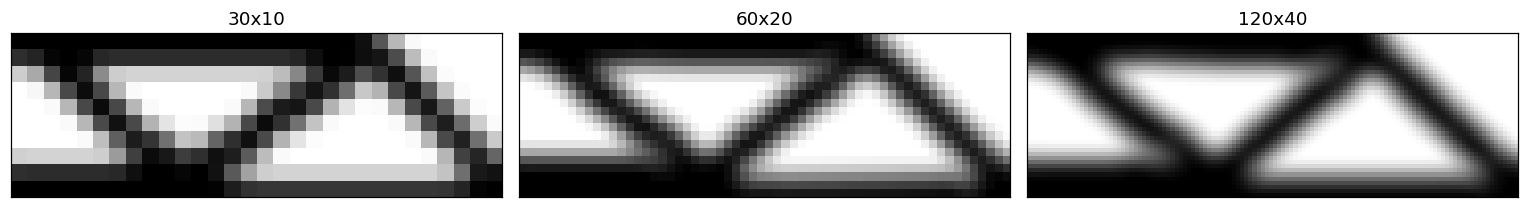

In [5]:
def damier(x, shape):
    z = np.asarray(x).reshape(shape)
    a, b, c, d = z[:-1, :-1], z[1:, :-1], z[:-1, 1:], z[1:, 1:]
    haut, bas = lambda t: t > 0.8, lambda t: t < 0.2
    return float(((haut(a) & haut(d) & bas(b) & bas(c)) | (bas(a) & bas(d) & haut(b) & haut(c))).mean())

def resout(shape, R, schedule, opt, n_it, normalize=False, tol=0.0):
    pb = ComplianceProblem("mbb", shape, volfrac=0.5, R=R, h=(60 / shape[0],) * 2, normalize=normalize)
    t0 = time.perf_counter()
    r = run(pb, opt, schedule, max_iter=n_it, tol=tol)
    rb = pb.rho_bar(torch.from_numpy(r.x)).detach().numpy()
    return pb, r, rb, np.array([h["C"] for h in r.history]), time.perf_counter() - t0

fig, ax = plt.subplots(1, 3, figsize=(14, 2.9))
print(f"{'maillage':>9} | {'R/h':>4} | {'C (200 it.)':>11} | {'% gris':>6} | {'% blocs en damier':>17} | volume | temps")
for a_, shape in zip(ax, [(30, 10), (60, 20), (120, 40)]):
    pb, r, rb, C, dt = resout(shape, 3.0, const, OC(), 200)
    print(f"{str(shape):>9} | {3.0 / (60 / shape[0]):4.1f} | {C[-1]:11.2f} | {100 * grise(rb):6.1f} | {100 * damier(rb, shape):17.1f} | {rb.mean():.6f} | {dt:.1f} s")
    montre(a_, rb, shape, f"{shape[0]}x{shape[1]}")
plt.tight_layout(); plt.show()

Les trois maillages donnent maintenant **la même forme** et des compliances voisines (écart d'environ 1 % sur un raffinement ×4, contre une forme qui changeait complètement au notebook 8), sans aucun damier. Raffiner le maillage précise le même design au lieu d'y ajouter des barres.

Le prix est visible : la moitié des éléments sont **gris** (frontières étalées sur une largeur de l'ordre de $R$), et la compliance, plus haute qu'au notebook 8, est celle d'un design qui a le droit d'être contraint en taille minimale. Un matériau gris n'est pas imprimable ni calculable de façon crédible ; on le raidit par projection.

## 4. La projection de Heaviside

On remplace la densité filtrée $\tilde\rho$ par une version *presque binaire*

$$
\hat\rho=\frac{\tanh(\beta\eta)+\tanh\!\big(\beta(\tilde\rho-\eta)\big)}{\tanh(\beta\eta)+\tanh\!\big(\beta(1-\eta)\big)},\qquad\eta=0{,}5 .
$$

C'est une marche douce centrée sur le seuil $\eta$ ; $\beta$ règle sa raideur. Propriétés (test C-PROJ-01/02) : $\hat\rho(0)=0$, $\hat\rho(1)=1$ pour tout $\beta$ ; croissante ; $\hat\rho(\eta)=\eta$ si $\eta=0{,}5$ ; $\beta\to0$ redonne l'identité (le code traite $\beta=0$ explicitement, la formule y étant 0/0 : **$\beta=0$ désactive la projection**, c'est l'équivalence avec top88) ; $\beta\to\infty$ donne un seuil. La dérivée $\partial\hat\rho/\partial\tilde\rho$ est grande près de $\eta$ et presque nulle ailleurs : une fois un élément éloigné de $\eta$, il devient quasi insensible.

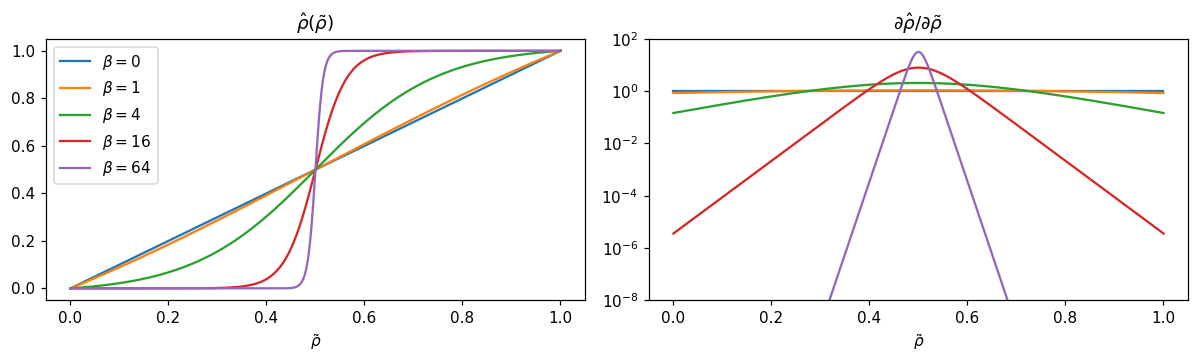

beta =    1 : f(0) = 0.0e+00, f(1) = 1.000000000000, f(0,5) = 0.500000000000, f(0,45) = 0.4459, f(0,55) = 0.5541
beta =   16 : f(0) = 0.0e+00, f(1) = 1.000000000000, f(0,5) = 0.500000000000, f(0,45) = 0.1680, f(0,55) = 0.8320
beta =   64 : f(0) = 0.0e+00, f(1) = 1.000000000000, f(0,5) = 0.500000000000, f(0,45) = 0.0017, f(0,55) = 0.9983
beta = 0 : identité exacte ? True


In [6]:
r = torch.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for beta in (0.0, 1.0, 4.0, 16.0, 64.0):
    rr = r.clone().requires_grad_()
    y = heaviside_projection(rr, beta)
    y.sum().backward()
    ax[0].plot(r, y.detach(), label=f"$\\beta={beta:g}$"); ax[1].plot(r, rr.grad, label=f"$\\beta={beta:g}$")
ax[0].set(xlabel=r"$\tilde\rho$", title=r"$\hat\rho(\tilde\rho)$"); ax[0].legend()
ax[1].set(xlabel=r"$\tilde\rho$", title=r"$\partial\hat\rho/\partial\tilde\rho$", yscale="log", ylim=(1e-8, 100))
plt.tight_layout(); plt.show()

for beta in (1.0, 16.0, 64.0):
    e = lambda v: float(heaviside_projection(torch.tensor(v), beta))
    print(f"beta = {beta:4.0f} : f(0) = {e(0.0):.1e}, f(1) = {e(1.0):.12f}, f(0,5) = {e(0.5):.12f}, f(0,45) = {e(0.45):.4f}, f(0,55) = {e(0.55):.4f}")
print("beta = 0 : identité exacte ?", bool(torch.equal(heaviside_projection(r, 0.0), r)))

## 5. Pourquoi une continuation : la projection d'emblée échoue

On optimise la même poutre ($60\times20$, $R=3$, $p=3$, volume 50 %, 300 itérations d'OC avec un déplacement limité à 0,1) avec $\beta$ fixé à 0, 4, 8, puis 16 **dès la première itération**. Comparaison à volume égal : la contrainte est tenue à $10^{-6}$ près, la colonne volume le montre.

beta fixé |  C finale |    C min | % gris |   volume


        0 |     249.2 |    249.2 |   50.8 | 0.500000


        4 |     217.6 |    217.6 |   27.0 | 0.500000


        8 |     568.9 |    433.2 |   71.8 | 0.500000


       16 |    6415.8 |    670.3 |   52.4 | 0.500000


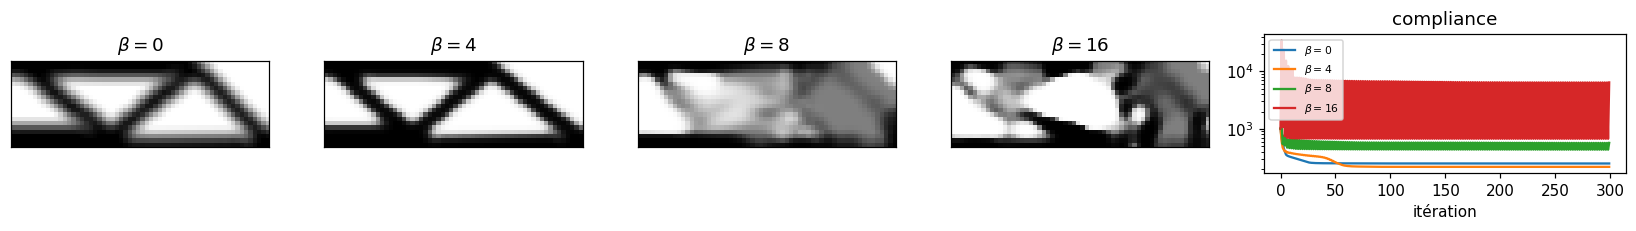

In [7]:
out5 = {}
print(f"{'beta fixé':>9} | {'C finale':>9} | {'C min':>8} | {'% gris':>6} | {'volume':>8}")
for beta in (0.0, 4.0, 8.0, 16.0):
    sch = Schedule(p=(3.0, 3.0), beta=(beta, beta), beta_s=(1.0, 1.0))
    pb, r, rb, C, dt = resout((60, 20), 3.0, sch, OC(move=0.1), 300)
    out5[beta] = (rb, C)
    print(f"{beta:9.0f} | {C[-1]:9.1f} | {C.min():8.1f} | {100 * grise(rb):6.1f} | {rb.mean():.6f}")

fig, ax = plt.subplots(1, 5, figsize=(15, 2.2), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.4]})
for a_, beta in zip(ax[:4], out5):
    montre(a_, out5[beta][0], (60, 20), f"$\\beta={beta:g}$")
for beta, (rb_, C_) in out5.items():
    ax[4].semilogy(C_, label=f"$\\beta={beta:g}$")
ax[4].set(xlabel="itération", title="compliance"); ax[4].legend(fontsize=7)
plt.tight_layout(); plt.show()

Plus $\beta$ est grand d'emblée, plus c'est mauvais : $\beta=4$ donne un résultat correct (compliance 217,6, un quart de gris), $\beta=8$ et surtout $\beta=16$ **échouent** : compliance finale très supérieure (569 et 6 416) et design resté flou ou incohérent. La courbe de $\beta=16$ n'est pas une convergence lente mais une **oscillation violente** entre 700 et 6 400 d'une itération à l'autre : l'OC, qui multiplie $\rho$ par $B^{1/2}$, n'arrive plus à suivre des sensibilités très raides.

Une explication plausible (non démontrée ici) : au départ la densité est uniforme à $\rho=0{,}5$, donc **exactement au seuil $\eta$**, là où la projection est la plus raide ; les sensibilités y sont amplifiées d'un facteur de l'ordre de $\beta$ et très hétérogènes. Quelle qu'en soit la cause, la leçon pratique est mesurée : **ne jamais imposer $\beta$ élevé d'emblée avec l'OC**. (Le notebook 10 montre que MMA supporte beaucoup mieux ces $\beta$ élevés, sans supprimer l'intérêt de la continuation.)

## 6. La continuation en $\beta$ et en $p$

La parade est de **monter progressivement** les paramètres durs : $\beta$ commence à 1 (presque l'identité : le problème est facile, la topologie se forme) puis double toutes les 50 itérations jusqu'à 16 (les contours se durcissent). De même $p$ peut partir de 1 (problème convexe : un seul minimum, pas de piège de topologie) et monter par pas de 0,5 vers 3. C'est `Schedule` (`optim/continuation.py`) :

```
étage k = it // every      p : +0,5 par étage      β, β_s : ×2 par étage     (plafonnés à leur valeur finale)
```

Chaque changement de paramètre modifie la fonction objectif vue par l'optimiseur : `run` appelle alors `optimizer.reset()` (C-OPT-04). L'OC n'a pas d'historique, donc le reset ne fait rien ; MMA (notebook 10) en a besoin. Le critère d'arrêt (C-OPT-05) est : variation maximale de $\mathbf x$ sous `tol` **et** tous les paramètres à leur valeur finale, sinon `max_iter` ; la cause est renvoyée dans `RunResult.stop_reason`. Tant que $\beta$ n'est pas à sa valeur finale, un petit déplacement ne suffit pas à arrêter, car l'étage suivant va changer le problème.

In [8]:
sch = Schedule(p=(1.0, 3.0), beta=(1.0, 16.0), beta_s=(1.0, 1.0), every=50)
print("calendrier (p, beta) aux itérations 0, 50, 100, 150, 200, 250 :")
print([(sch.at(i)["p"], sch.at(i)["beta"]) for i in (0, 50, 100, 150, 200, 250)])
print("étape finale atteinte à l'itération 200 ?", sch.is_final(199), sch.is_final(200))
print(run.__doc__)

calendrier (p, beta) aux itérations 0, 50, 100, 150, 200, 250 :
[(1.0, 1.0), (1.5, 2.0), (2.0, 4.0), (2.5, 8.0), (3.0, 16.0), (3.0, 16.0)]
étape finale atteinte à l'itération 200 ? False True
Minimise `problem` with `optimizer`, following `schedule`.

    `problem.set_continuation(params)` is called whenever a schedule value changes and
    `optimizer.reset()` right after (C-OPT-04); `problem.evaluate(x)` takes a flat float tensor
    (requires_grad) and returns an object with `.J`, `.g` (list of scalar tensors) and `.terms`.
    Stops when max|dx| < tol AND every continuation parameter is final, or after `max_iter` iterations
    (C-OPT-05); the reason is returned in `RunResult.stop_reason`.
    


                calendrier |  C finale | % gris |    volume | dx final | cause d'arrêt


   p=3, beta=0 (référence) |     249.2 |   50.8 |  0.500000 |   0.0083 | max_iter (300 it.)


           beta 1->16, p=3 |     191.7 |    2.8 |  0.500000 |   0.1000 | max_iter (300 it.)


      p 1->3 et beta 1->16 |     197.5 |    6.4 |  0.500000 |   0.1000 | max_iter (300 it.)


       p 1->3 seul, beta=0 |     255.7 |   55.1 |  0.500000 |   0.0194 | max_iter (300 it.)


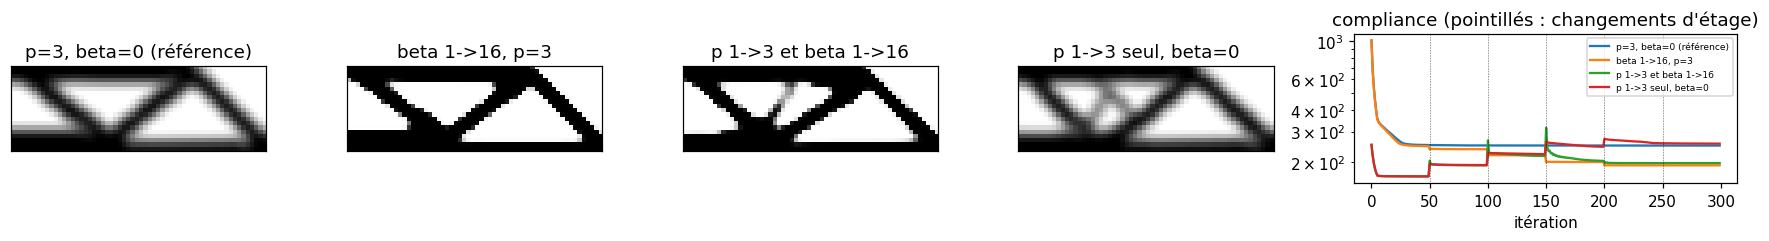

In [9]:
cas6 = {
    "p=3, beta=0 (référence)":      Schedule(p=(3.0, 3.0), beta=(0.0, 0.0), beta_s=(1.0, 1.0)),
    "beta 1->16, p=3":              Schedule(p=(3.0, 3.0), beta=(1.0, 16.0), beta_s=(1.0, 1.0), every=50),
    "p 1->3 et beta 1->16":         Schedule(p=(1.0, 3.0), beta=(1.0, 16.0), beta_s=(1.0, 1.0), every=50),
    "p 1->3 seul, beta=0":          Schedule(p=(1.0, 3.0), beta=(0.0, 0.0), beta_s=(1.0, 1.0), every=50),
}
out6 = {}
print(f"{'calendrier':>26} | {'C finale':>9} | {'% gris':>6} | {'volume':>9} | {'dx final':>8} | cause d'arrêt")
for nom, sch in cas6.items():
    pb, r, rb, C, dt = resout((60, 20), 3.0, sch, OC(move=0.1), 300, tol=1e-3)
    out6[nom] = (rb, C, r)
    print(f"{nom:>26} | {C[-1]:9.1f} | {100 * grise(rb):6.1f} | {rb.mean():9.6f} | {r.history[-1]['dx']:8.4f} | {r.stop_reason} ({len(C)} it.)")

fig, ax = plt.subplots(1, 5, figsize=(16, 2.3), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.5]})
for a_, (nom, (rb_, C_, r_)) in zip(ax[:4], out6.items()):
    montre(a_, rb_, (60, 20), nom)
for nom, (rb_, C_, r_) in out6.items():
    ax[4].semilogy(C_, label=nom)
for k in range(1, 6): ax[4].axvline(50 * k, color="k", lw=0.4, ls=":")
ax[4].set(xlabel="itération", title="compliance (pointillés : changements d'étage)"); ax[4].legend(fontsize=6)
plt.tight_layout(); plt.show()

À volume égal :
- La **continuation en $\beta$** change tout : le design devient presque binaire (2,8 % de gris au lieu de 51 %) et la compliance **baisse de 249 à 192**, alors que le même $\beta=16$ imposé d'emblée échouait (§5). Chaque nouvel étage fait remonter la compliance un instant (le design vient d'être raidi) puis la ramène plus bas (courbe).
- La **continuation en $p$**, ici, n'apporte **rien** : avec $\beta$ elle fait un peu moins bien que $\beta$ seul (197,5 contre 191,7), et sans $\beta$ elle ne change presque rien (255,7 contre 249,2). Au notebook 8 on avait vu qu'un design de $p=2$ battait celui de $p=3$ en l'absence de filtre ; avec le filtre, le problème est mieux posé et le gain ne se présente pas sur ce cas. On ne suppose donc pas qu'une continuation aide : on la **mesure**, et on garde $p$ constant pour le bras de drone tant qu'un gain n'est pas démontré.
- **Aucune des quatre exécutions ne satisfait le critère d'arrêt** (cause « max_iter ») : avec les $\beta$ élevés, la variation maximale de $\mathbf x$ reste égale à la limite de déplacement de l'OC (0,1) : quelques éléments aux frontières oscillent entre deux états. La compliance, elle, est stable à moins de 1 % sur les dernières dizaines d'itérations ; le notebook 10 remplace l'OC par MMA, qui converge réellement.

 maillage |  C finale | % gris | % damier | volume   | temps


 (30, 10) |     191.6 |    0.0 |      0.0 | 0.500000 | 1.2 s


 (60, 20) |     191.7 |    2.8 |      0.0 | 0.500000 | 2.8 s


(120, 40) |     195.7 |    7.0 |      0.0 | 0.500000 | 14.9 s


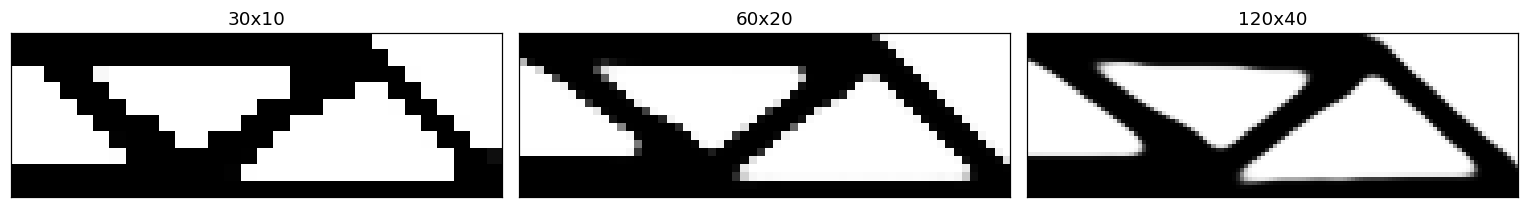

In [10]:
# maillage fin : continuation beta 1 -> 16 sur les trois maillages, R fixe = 3 (physique)
sch = Schedule(p=(3.0, 3.0), beta=(1.0, 16.0), beta_s=(1.0, 1.0), every=50)
fig, ax = plt.subplots(1, 3, figsize=(14, 2.9))
print(f"{'maillage':>9} | {'C finale':>9} | {'% gris':>6} | {'% damier':>8} | volume   | temps")
for a_, shape in zip(ax, [(30, 10), (60, 20), (120, 40)]):
    pb, r, rb, C, dt = resout(shape, 3.0, sch, OC(move=0.1), 300)
    print(f"{str(shape):>9} | {C[-1]:9.1f} | {100 * grise(rb):6.1f} | {100 * damier(rb, shape):8.1f} | {rb.mean():.6f} | {dt:.1f} s")
    montre(a_, rb, shape, f"{shape[0]}x{shape[1]}")
plt.tight_layout(); plt.show()

Sur trois maillages, la même forme revient, avec des contours bien plus nets (0 à 7 % de gris) et une compliance qui varie de 2 % (191,6 ; 191,7 ; 195,7) : un maillage plus fin donne des contours plus précis, pas d'autres barres. (Le plus fin est un peu moins bon, probablement parce qu'à 300 itérations il n'est pas aussi convergé ; nous ne l'avons pas vérifié.)

## 7. La chaîne entière est dérivable

Toute la chaîne $\mathbf x\to$ filtre $\to$ projection $\to$ SIMP $\to$ résolution (adjoint) $\to\mathcal{C}$ est différentiable, ce qui évite d'écrire à la main la dérivée du filtre ou de la projection. On le vérifie par différences finies centrées sur une petite poutre ($12\times6$), avec une projection raide ($\beta=8$) et un filtre ($R=2$) : si une des dérivées était fausse ou absente, l'écart serait grand.

In [11]:
pb = ComplianceProblem("mbb", (12, 6), volfrac=0.5, R=2.0, beta=8.0)
x = torch.rand(72, generator=torch.Generator().manual_seed(0)).requires_grad_()
res = pb.evaluate(x)
res.J.backward()
g = x.grad.detach().clone()
idx = list(range(0, 72, 5))
fd = []
for i in idx:
    e = torch.zeros(72); e[i] = 1e-5
    fd.append(((pb.evaluate(x.detach() + e).J - pb.evaluate(x.detach() - e).J) / 2e-5).item())
fd = np.array(fd)
print(f"{len(idx)} dérivées comparées ; écart relatif max aux différences finies : {float(np.abs(fd - g[idx].numpy()).max() / g.abs().max()):.1e}")
print(f"gradient : min {float(g.min()):.1f}, max {float(g.max()):.2f} (négatif partout : plus de matière ne peut pas nuire, même à travers le filtre et la projection)")

15 dérivées comparées ; écart relatif max aux différences finies : 1.2e-08
gradient : min -2380.3, max -1.45 (négatif partout : plus de matière ne peut pas nuire, même à travers le filtre et la projection)


## Bilan

| Constat | Où c'est dans le code |
|---|---|
| Filtre conique normalisé : conserve les constantes aux bords, reste dans $[0,1]$, identité si $R\le h$, = oracle dense | `DensityFilter`, tests C-FILT-01 à 03 |
| Le gradient traverse le filtre (= filtre transposé normalisé), vérifié par `gradcheck` | C-FILT-04 |
| La boucle avec filtre reproduit top88 (`ft=2`) à $10^{-11}$ ; benchmark MBB à ±2 % | `ComplianceProblem`, `run`, C-OPT-02 |
| Avec $R$ physique fixe, trois maillages donnent la même forme et plus de damiers | §3 |
| Heaviside : $\hat\rho(0)=0$, $\hat\rho(1)=1$, croissante, $\beta=0$ = identité exacte ; $\beta$ mutable hors graphe | `heaviside_projection`, C-PROJ-01 à 03 |
| $\beta$ fort d'emblée échoue ; la continuation en $\beta$ (1 à 16) donne un design net et bien meilleur | `Schedule`, §5, §6 |
| La continuation en $p$ n'a pas aidé sur ce cas : à mesurer, pas à supposer | §6 |
| Masques passifs : $\bar\rho=1$ sur S et $0$ sur V exactement, sensibilité nulle sur ces zones | `DensityPipeline`, C-MASK-01 |
| Chaîne complète dérivable (filtre, projection, SIMP, adjoint) | §7 |

**Limites à retenir.**
- **Le filtre contrôle la largeur des barres, pas des trous**, et il n'élimine pas les frontières grises : il faut la projection. La projection par un seul seuil $\eta=0{,}5$ fait légèrement **grossir ou rétrécir** les membrures selon les conditions ; les formulations « robustes » (érodé / dilaté) qui contrôlent cela sortent du périmètre.
- **Le rayon $R$ est un paramètre de conception** : pour le projet, c'est la largeur de buse multipliée par un facteur (FORMALISM §6).
- **Le volume est calculé sur $\bar\rho$** ; si la pièce finale est seuillée à 0,5 le volume change un peu.
- **Les calendriers** (50 itérations par étage, $\beta$ doublé) sont des réglages standard, pas des optima.
- **Le surplomb** (leçon 12) s'ajoute à cette chaîne entre la projection et les masques ; `DensityPipeline` refuse pour l'instant l'option (`NotImplementedError`).

**Pour expérimenter.** (i) Au §3, doublez $R$ : que deviennent la compliance et le nombre de barres ? (ii) Au §5, essayez $\beta=16$ avec `OC(move=0.02)` : le déplacement limité sauve-t-il la projection d'emblée ? (iii) Au §6, changez `every` à 25 ou 100 : compromis entre coût et qualité. (iv) Au §6, partez de $\eta=0{,}4$ et $\eta=0{,}6$ (argument de `DensityPipeline` ; modifiez `pb.pipeline.eta`) : le volume de la pièce et ses membrures changent-ils ?

*Suite : leçon 10 (optimiseurs sous contraintes : OC, MMA, descente de gradient projetée). Voir le [plan des leçons](README.md).*